# Frame table review

Reads a built frame table (`scripts/build_frame_table.py`), its profile and report
(`scripts/profile_frame_table.py`) and a few raw shots with `fusion_eq.io.load_shot`.
Cells are run manually, top to bottom. Sections follow `docs/FRAME_TABLE.md`, "Review
notebook". Plots that need individual frames use a fixed-seed sample of shots; summary
statistics use the whole table. The first cell selects the build to review: the smoke
output by default, the full table once it exists.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fusion_eq import frame_table as ft
from fusion_eq.io import load_shot
from fusion_eq.machines import machine_config

# Build to review. Switch both to the full table once it is built:
#   TABLE_DIR = Path("../../data/processed/frame_table"); REPORT_DIR = Path("../reports/frame_table")
TABLE_DIR = Path("../../data/processed/frame_table")
REPORT_DIR = Path("../reports/frame_table")
QA_TABLE = Path("../reports/qa/qa_per_shot.parquet")
SMOKE_FILE = Path("../reports/frame_table/smoke_shots.json")
SEED = 0

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
SPLITS = [s for s in ("diii_d_train", "diii_d_public_test", "mast_public_test")
          if ft.table_path(s, TABLE_DIR).is_file()]
MACHINE_OF = {"diii_d_train": "DIII-D", "diii_d_public_test": "DIII-D", "mast_public_test": "MAST"}


def read(split, columns=None, shots=None):
    """Rows of one split of the reviewed build."""
    return ft.read_frame_table(split, columns, shots, root=TABLE_DIR)


build = json.loads((TABLE_DIR / "build.json").read_text())
index = pd.read_parquet(TABLE_DIR / "shot_index.parquet")
PARAMS = build["params"]
print(f"build {build['timestamp']}, commit {str(build['repo_commit'])[:10]}, {build['runtime_s']:.0f} s")
print("params:", PARAMS)
print("splits present:", SPLITS)

build 2026-10-06T18:41:50+00:00, commit 12da37629d, 329 s
params: {'window_ms': 2.0, 'rate_window_ms': 10.0, 'max_gap_ms': 5.0, 'thomson_tol_ms': 20.0, 'align_ip': True, 'psi_summary': True}
splits present: ['diii_d_train', 'diii_d_public_test', 'mast_public_test']


## 1. Build summary

Shot and frame counts per split, shots that produced no rows, and the acceptance table
from the report. The report is written by `scripts/profile_frame_table.py`; when it is
missing, the cell says so.

In [2]:
summary = index.groupby(["split", "machine"], observed=True).agg(
    shots=("shot", "size"), frames=("n_frames", "sum"), errors=("error", lambda s: int(s.notna().sum())),
    nan_currents=("mag_has_nan", "sum"), no_core_thomson=("ts_core_any_valid", lambda s: int((~s.fillna(False)).sum())))
display(summary)
errors = index.loc[index["error"].notna(), ["split", "shot", "error"]]
print(f"{len(errors)} shots with errors")
display(errors)

report = REPORT_DIR / "frame_table_report.md"
if report.is_file():
    lines = report.read_text().splitlines()
    print("\n".join(l for l in lines if l.startswith("| T") or l.startswith("| Id") or l.startswith("| ---")))
else:
    print(f"no report at {report}; run scripts/profile_frame_table.py --table-dir {TABLE_DIR} --out {REPORT_DIR}")

,,shots,frames,errors,nan_currents,no_core_thomson
split,machine,,,,,
diii_d_public_test,DIII-D,874,193359,0,0,6
diii_d_train,DIII-D,7041,1559340,0,0,62
mast_public_test,MAST,1206,69075,0,114,1


0 shots with errors


,split,shot,error


| Id | Check | Status | Headline |
| --- | --- | --- | --- |
| T1 | Row and shot counts | pass | 9121 shots, 1821774 frames |
| T2 | Keys | pass | unique keys, increasing time |
| T3 | Labels untouched | pass | exact copies |
| T4 | Input completeness | review | see per split |
| T5 | Shot-level flags against QA | pass | rates match, directions match, NaN count matches |
| T6 | Ip at the first frame | pass | minimum 0.172 |
| T7 | Thomson coverage against QA | review | QA: about 97% covered; 53 / 6 / 1 shots without a profile |
| T8 | Resampling forms agree | review | |nearest - mean| / std(mean) |
| --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- |


In [3]:
display(index[["split", "shot", "n_frames", "mag_rate_hz", "mag_has_nan", "ip_direction", "tf_direction",
               "ip_fix", "ip_shift_ms", "ts_core_any_valid", "ts_edge_any_valid", "inputs_complete_frac"]]
        .sort_values(["split", "shot"]).head(40))
print("mag_rate_hz by machine:")
display(pd.crosstab(index["machine"], index["mag_rate_hz"]))

,split,shot,n_frames,mag_rate_hz,mag_has_nan,ip_direction,tf_direction,ip_fix,ip_shift_ms,ts_core_any_valid,ts_edge_any_valid,inputs_complete_frac
0,diii_d_public_test,0047b7837b,240,20000,False,1,-1,organizers,-3275.215332,True,True,1.0
1,diii_d_public_test,00b2ec09d2,328,2000,False,1,-1,alignment,-130.412933,True,True,1.0
2,diii_d_public_test,016318d6ae,231,20000,False,-1,-1,organizers,-3293.208984,True,True,1.0
3,diii_d_public_test,0164ba5e59,270,20000,False,1,1,organizers,-3118.554688,True,True,1.0
4,diii_d_public_test,01855ba85a,357,20000,False,1,-1,organizers,-3135.503662,True,True,1.0
5,diii_d_public_test,018b2070e3,150,20000,False,1,-1,organizers,-3101.715576,True,True,1.0
6,diii_d_public_test,01a875f7a7,76,2000,False,1,-1,alignment,28.587080,True,True,1.0
7,diii_d_public_test,01e0dadbf3,154,20000,False,1,-1,organizers,-3187.026611,True,False,1.0
8,diii_d_public_test,024469e912,238,20000,False,1,-1,organizers,-3275.214355,True,True,1.0
9,diii_d_public_test,0245a958b6,283,2000,False,1,1,alignment,-236.912933,True,True,1.0


mag_rate_hz by machine:


mag_rate_hz,1900,2000,5000,20000
machine,,,,
DIII-D,0,2397,0,5518
MAST,114,0,1092,0


## 2. Resampling of currents (A1, A2)

One shot of each kind in the smoke set: the raw plasma current and solenoid current
inside the EFIT window with the two frame values, `__nearest` and `__mean`, drawn over
them. Then the T8 distributions: `__nearest` minus `__mean` relative to the spread of
`__mean`, per current column and recording rate. The two forms are compared on the
ridge score in the baseline phase; this section only checks that both read the trace
correctly and shows where they differ.

In [4]:
# Kinds of the smoke set, from the QA table, restricted to shots present in this build.
sys.path.insert(0, "../scripts")
from select_smoke_shots import select  # noqa: E402

qa = pd.read_parquet(QA_TABLE)
kinds = {kind: [s for s in shots if s in set(index["shot"])] for kind, shots in select(qa, per_kind=50).items()}
kinds = {kind: shots for kind, shots in kinds.items() if shots}
for kind, shots in kinds.items():
    print(f"{kind:22s} {len(shots)} shots in this build, first {shots[:2]}")
index_by_shot = index.set_index("shot")

d3d_20khz              50 shots in this build, first ['00000a10ac', '0011c2afc9']
d3d_2khz               50 shots in this build, first ['00000c4a7b', '0003ff34e7']
d3d_negative_ip        50 shots in this build, first ['00000a10ac', '001bc5a4ae']
d3d_no_thomson         50 shots in this build, first ['043557db5d', '04c9fd413a']
d3d_under_10_frames    42 shots in this build, first ['01a391fd67', '04c9fd413a']
d3d_test               50 shots in this build, first ['0047b7837b', '00b2ec09d2']
mast_without_nan       50 shots in this build, first ['0035568738', '00398d18da']
mast_with_nan          50 shots in this build, first ['018ab61eba', '09abe0daef']


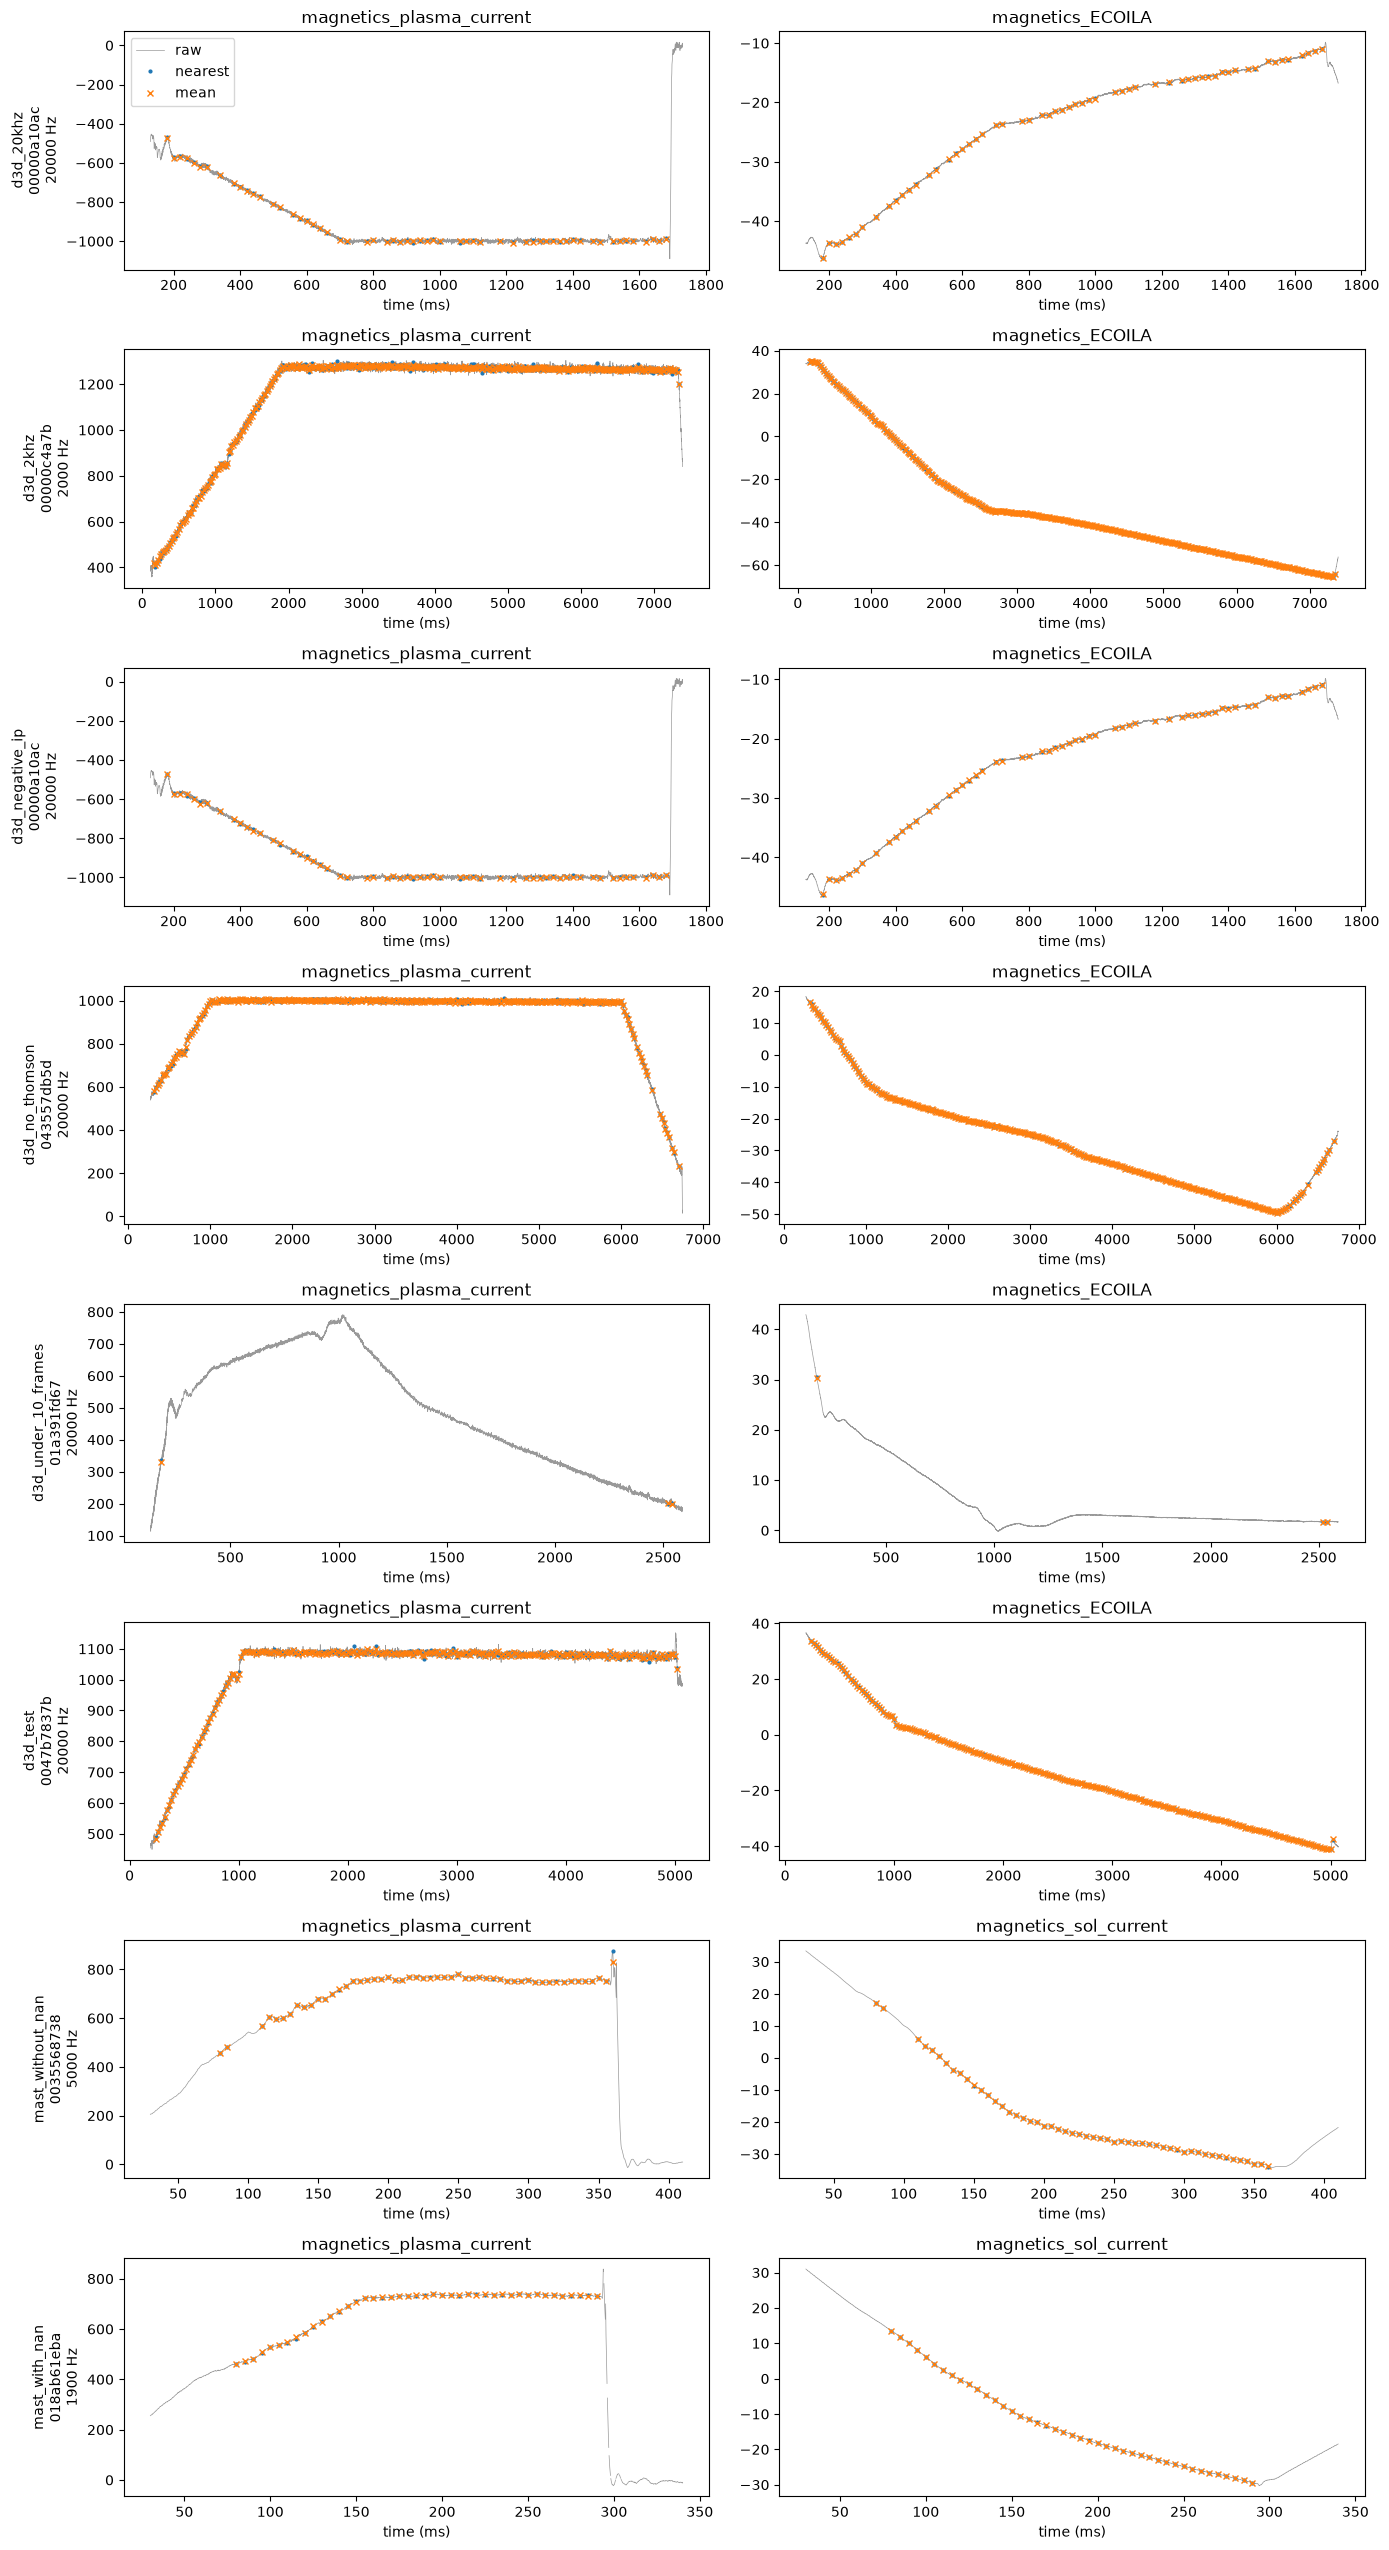

In [5]:
def raw_current(shot, column):
    """(time_ms, values) of one current column on its own time axis, in float64."""
    axis = shot[shot.machine.time_axis_column(column)]
    return np.asarray(axis, dtype=np.float64), np.asarray(shot[column], dtype=np.float64)


def plot_forms(ax, shot, column, frames, name, pad_ms=50.0):
    t, v = raw_current(shot, column)
    lo, hi = frames["time_ms"].min() - pad_ms, frames["time_ms"].max() + pad_ms
    inside = (t >= lo) & (t <= hi)
    ax.plot(t[inside], v[inside], lw=0.5, color="0.6", label="raw")
    ax.plot(frames["time_ms"], frames[f"{name}__nearest"], ".", ms=4, label="nearest")
    ax.plot(frames["time_ms"], frames[f"{name}__mean"], "x", ms=4, label="mean")
    ax.set_title(f"{column}")
    ax.set_xlabel("time (ms)")


fig, axes = plt.subplots(len(kinds), 2, figsize=(14, 3.2 * len(kinds)), squeeze=False)
for row, (kind, shots) in zip(axes, kinds.items()):
    shot_id = shots[0]
    info = index_by_shot.loc[shot_id]
    cfg = machine_config(info["machine"])
    columns = ["efit_times", "magnetics_time", "magnetics_plasma_current_times", cfg.ip_column, cfg.solenoid_column]
    shot = load_shot(info["path"], columns, align_ip=PARAMS["align_ip"])
    frames = read(info["split"], ["time_ms", "ip__nearest", "ip__mean", "sol__nearest", "sol__mean"], [shot_id])
    plot_forms(row[0], shot, cfg.ip_column, frames, "ip")
    plot_forms(row[1], shot, cfg.solenoid_column, frames, "sol")
    row[0].set_ylabel(f"{kind}\n{shot_id}\n{int(info['mag_rate_hz'])} Hz")
axes[0, 0].legend(loc="best")
fig.tight_layout()

In [6]:
# T8: nearest minus mean relative to the spread of mean, per column and recording rate.
def t8_table(split, signals):
    cols = ["mag_rate_hz"] + [f"{s}__nearest" for s in signals] + [f"{s}__mean" for s in signals]
    df = read(split, cols)
    rows = []
    for rate, sub in df.groupby("mag_rate_hz"):
        for s in signals:
            diff = (sub[f"{s}__nearest"] - sub[f"{s}__mean"]).to_numpy(dtype=np.float64)
            spread = np.nanstd(sub[f"{s}__mean"].to_numpy(dtype=np.float64))
            rel = np.abs(diff[np.isfinite(diff)]) / spread if spread > 0 else np.array([])
            if rel.size:
                rows.append({"split": split, "rate_hz": int(rate), "signal": s, "frames": int(rel.size),
                             "p50": np.median(rel), "p90": np.percentile(rel, 90), "p99": np.percentile(rel, 99),
                             "max": rel.max()})
    return pd.DataFrame(rows)


t8 = []
for split in SPLITS:
    cfg = machine_config(MACHINE_OF[split])
    signals = ["ip", "sol", "tf", cfg.shaping_coil_columns[0], cfg.shaping_coil_columns[-1]]
    t8.append(t8_table(split, signals))
t8 = pd.concat(t8, ignore_index=True)
display(t8.round(5))

,split,rate_hz,signal,frames,p50,p90,p99,max
0,diii_d_train,2000,ip,495981,0.00719,0.01887,0.03447,0.24418
1,diii_d_train,2000,sol,495981,0.00150,0.00393,0.00710,0.01487
2,diii_d_train,2000,tf,495981,0.00381,0.01047,0.02101,0.10817
3,diii_d_train,2000,magnetics_F1A,495981,0.00870,0.02162,0.03644,0.13923
4,diii_d_train,2000,magnetics_F9B,495981,0.00196,0.00604,0.01207,0.04373
5,diii_d_train,20000,ip,1063359,0.00371,0.00956,0.01715,0.09444
6,diii_d_train,20000,sol,1063359,0.00127,0.00309,0.00516,0.01283
7,diii_d_train,20000,tf,1063359,0.00255,0.00761,0.01747,0.06978
8,diii_d_train,20000,magnetics_F1A,1063359,0.00857,0.01920,0.03071,0.10694
9,diii_d_train,20000,magnetics_F9B,1063359,0.00113,0.00401,0.00918,0.03645


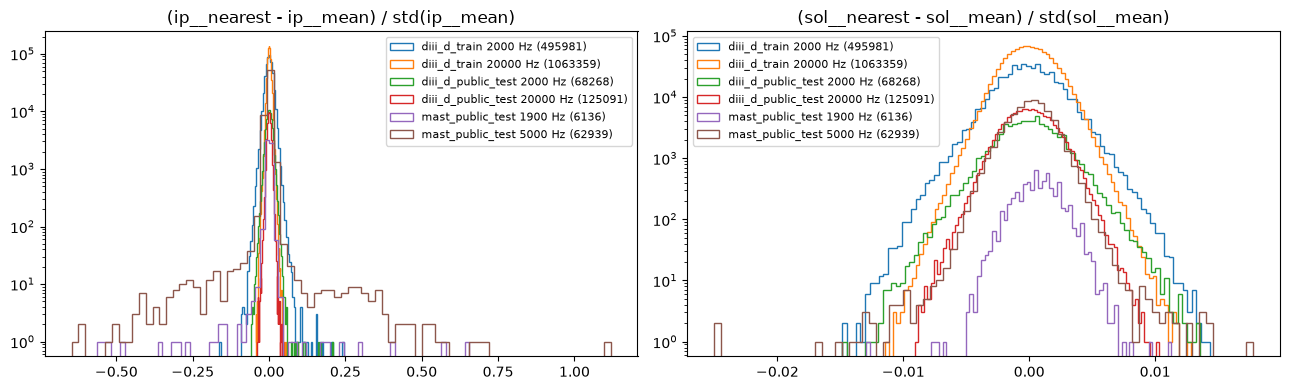

In [7]:
# Distribution of the relative difference for Ip and the solenoid, per split and rate.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, signal in zip(axes, ["ip", "sol"]):
    for split in SPLITS:
        df = read(split, ["mag_rate_hz", f"{signal}__nearest", f"{signal}__mean"])
        for rate, sub in df.groupby("mag_rate_hz"):
            diff = (sub[f"{signal}__nearest"] - sub[f"{signal}__mean"]).to_numpy(dtype=np.float64)
            spread = np.nanstd(sub[f"{signal}__mean"].to_numpy(dtype=np.float64))
            rel = diff[np.isfinite(diff)] / spread if spread > 0 else np.array([])
            if rel.size:
                ax.hist(rel, bins=80, histtype="step", label=f"{split} {int(rate)} Hz ({rel.size})")
    ax.set_yscale("log")
    ax.set_title(f"({signal}__nearest - {signal}__mean) / std({signal}__mean)")
    ax.legend(fontsize=8)
fig.tight_layout()

## 3. Rates of change (A4)

The slope drawn against the raw trace through a current ramp: for one 20 kHz and one
2 kHz DIII-D shot, the frames with the largest absolute `ip__rate`, each with a segment
of slope `ip__rate` and length `rate_window_ms` centred on the frame. Then the spread of
`ip__rate` and of one shaping-coil rate on flat-top frames (`ip_over_peak` above 0.9),
compared between the 20 kHz and 2 kHz groups. A wider spread in one group means the
window is too short for that rate.

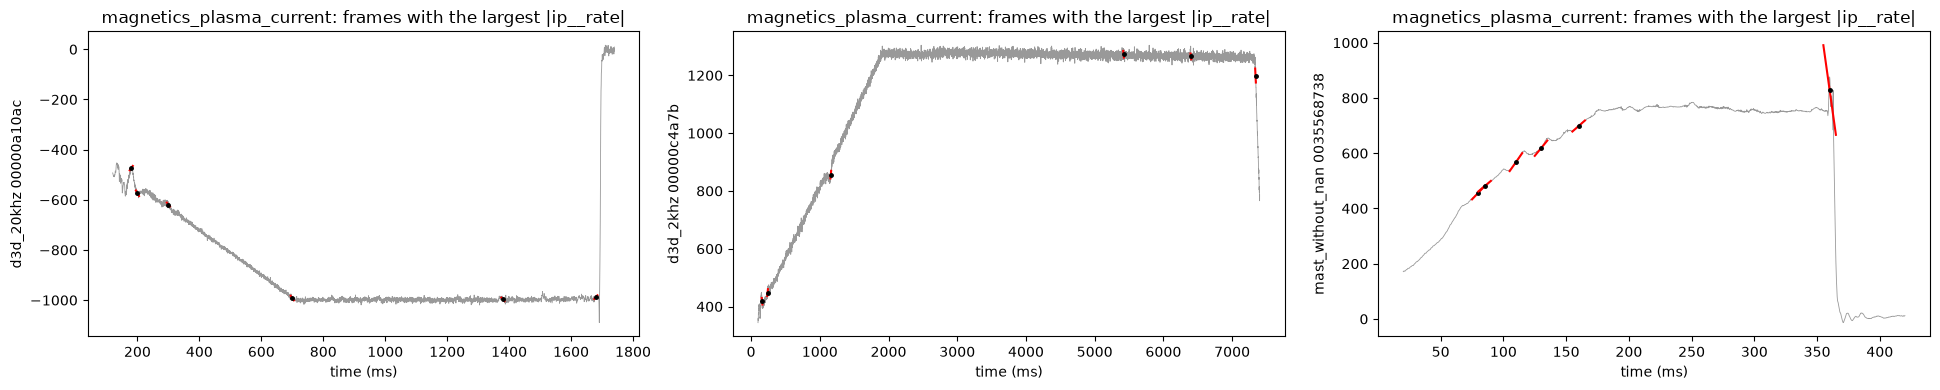

In [8]:
def plot_slopes(ax, shot, frames, name, column, n_frames=6, pad_ms=60.0):
    t, v = raw_current(shot, column)
    top = frames.loc[frames[f"{name}__rate"].abs().nlargest(n_frames).index].sort_values("time_ms")
    lo, hi = top["time_ms"].min() - pad_ms, top["time_ms"].max() + pad_ms
    inside = (t >= lo) & (t <= hi)
    ax.plot(t[inside], v[inside], lw=0.6, color="0.6", label="raw")
    half = PARAMS["rate_window_ms"] / 2
    for _, f in top.iterrows():
        slope_per_ms = f[f"{name}__rate"] / 1000.0
        ax.plot([f["time_ms"] - half, f["time_ms"] + half],
                [f[f"{name}__mean"] - slope_per_ms * half, f[f"{name}__mean"] + slope_per_ms * half], "r-", lw=1.5)
        ax.plot(f["time_ms"], f[f"{name}__mean"], "k.", ms=5)
    ax.set_xlabel("time (ms)")
    ax.set_title(f"{column}: frames with the largest |{name}__rate|")


ramp_kinds = [k for k in ("d3d_20khz", "d3d_2khz", "mast_without_nan") if k in kinds]
fig, axes = plt.subplots(1, len(ramp_kinds), figsize=(6.5 * len(ramp_kinds), 4), squeeze=False)
for ax, kind in zip(axes[0], ramp_kinds):
    shot_id = kinds[kind][0]
    info = index_by_shot.loc[shot_id]
    cfg = machine_config(info["machine"])
    shot = load_shot(info["path"], ["efit_times", "magnetics_time", "magnetics_plasma_current_times", cfg.ip_column],
                     align_ip=PARAMS["align_ip"])
    frames = read(info["split"], ["time_ms", "ip__mean", "ip__rate"], [shot_id])
    plot_slopes(ax, shot, frames, "ip", cfg.ip_column)
    ax.set_ylabel(f"{kind} {shot_id}")
fig.tight_layout()

1214019 flat-top frames of 1559340
ip__rate


,0.01,0.05,0.25,0.50,0.75,0.95,0.99
mag_rate_hz,,,,,,,
2000,-2178.74,-1340.02,-484.39,21.53,519.11,1315.25,2010.56
20000,-1940.24,-1083.47,-359.09,3.21,366.43,1055.70,1806.12


magnetics_F1A__rate


,0.01,0.05,0.25,0.50,0.75,0.95,0.99
mag_rate_hz,,,,,,,
2000,-539.94,-305.13,-101.81,-4.08,92.20,293.87,594.78
20000,-416.52,-224.63,-72.29,-4.29,61.55,204.61,396.34


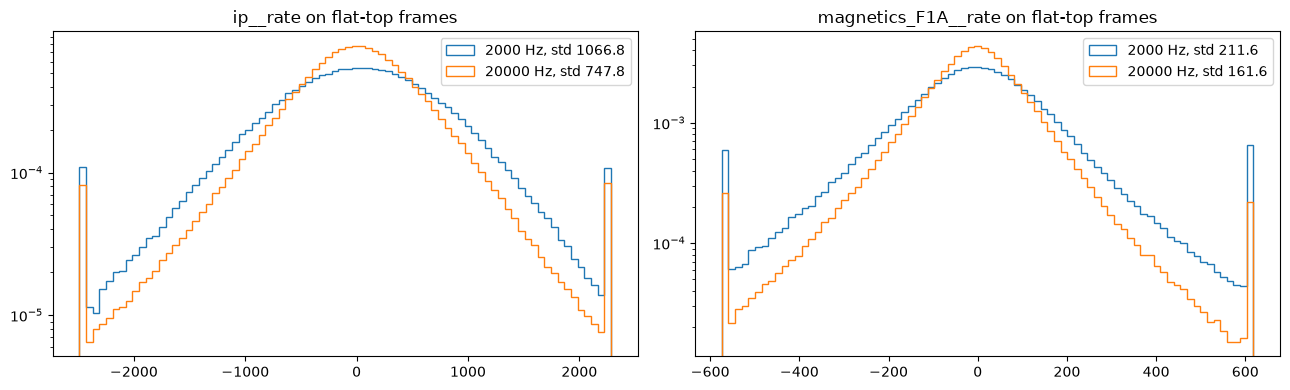

In [9]:
# Spread of rates on flat-top frames, 20 kHz against 2 kHz (DIII-D training table).
FLAT_TOP = 0.9
QUANTILES = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
if "diii_d_train" in SPLITS:
    coil = machine_config("DIII-D").shaping_coil_columns[0]
    df = read("diii_d_train", ["mag_rate_hz", "ip_over_peak", "ip__rate", f"{coil}__rate"])
    flat = df[df["ip_over_peak"] > FLAT_TOP]
    print(f"{len(flat)} flat-top frames of {len(df)}")
    for col in ("ip__rate", f"{coil}__rate"):
        print(col)
        display(flat.groupby("mag_rate_hz")[col].quantile(QUANTILES).unstack().round(2))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, col in zip(axes, ("ip__rate", f"{coil}__rate")):
        values = flat[col].dropna()
        lo, hi = values.quantile([0.005, 0.995])
        bins = np.linspace(lo, hi, 81)
        for rate, sub in flat.groupby("mag_rate_hz"):
            ax.hist(sub[col].dropna().clip(lo, hi), bins=bins, histtype="step", density=True,
                    label=f"{int(rate)} Hz, std {sub[col].std():.1f}")
        ax.set_title(f"{col} on flat-top frames")
        ax.set_yscale("log")
        ax.legend()
    fig.tight_layout()

## 4. Thomson in time (A3)

`__interp` against `__nearest` for the core electron pressure; coverage as a function of
the tolerance, per machine, from the stored time-distance columns; and the shots with
no usable Thomson. The validity flag in the table uses `thomson_tol_ms` of the build;
the coverage curve shows what any other tolerance would give without a rebuild.

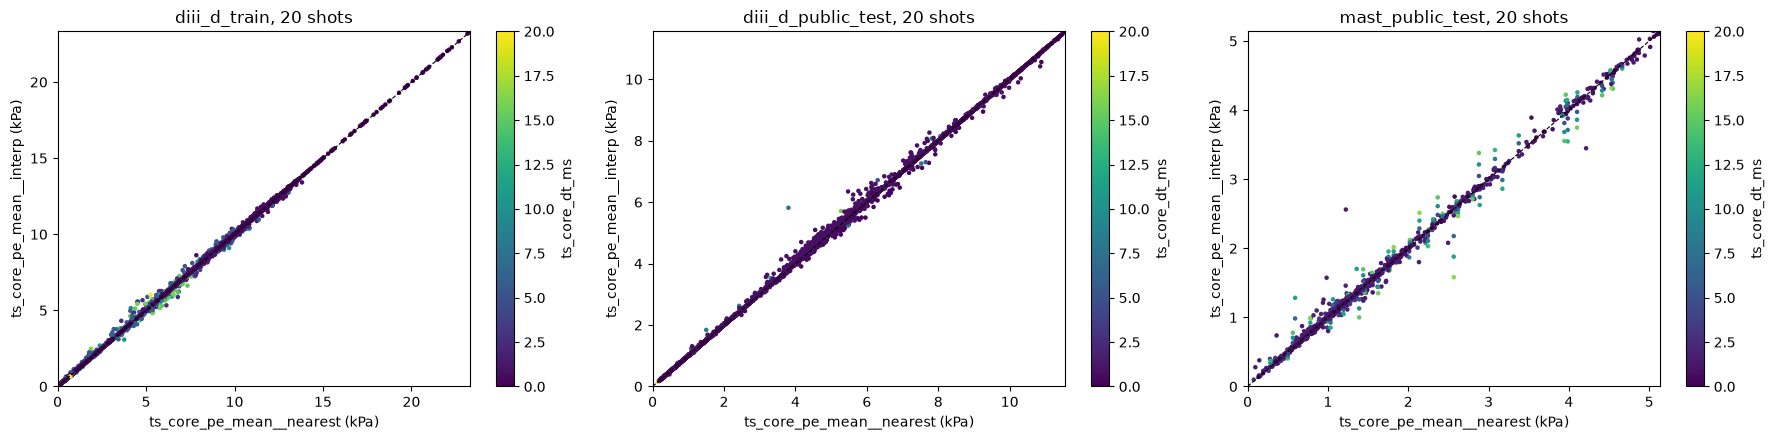

In [10]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6 * len(SPLITS), 4.5), squeeze=False)
for ax, split in zip(axes[0], SPLITS):
    shots = sorted(index.loc[(index["split"] == split) & index["error"].isna(), "shot"])
    sample = sorted(rng.choice(shots, size=min(20, len(shots)), replace=False)) if shots else []
    df = read(split, ["ts_core_pe_mean__interp", "ts_core_pe_mean__nearest", "ts_core_dt_ms", "ts_core_gap_ms"], sample)
    sc = ax.scatter(df["ts_core_pe_mean__nearest"], df["ts_core_pe_mean__interp"], c=df["ts_core_dt_ms"], s=5,
                    cmap="viridis", vmin=0, vmax=PARAMS["thomson_tol_ms"])
    lim = np.nanpercentile(df[["ts_core_pe_mean__nearest", "ts_core_pe_mean__interp"]].to_numpy(), 99.5)
    ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("ts_core_pe_mean__nearest (kPa)")
    ax.set_ylabel("ts_core_pe_mean__interp (kPa)")
    ax.set_title(f"{split}, {len(sample)} shots")
    fig.colorbar(sc, ax=ax, label="ts_core_dt_ms")
fig.tight_layout()

,split,system,frames_within_build_tol,frames_within_10ms,frames_without_any
0,diii_d_train,core,0.9852,0.9730,0.0044
1,diii_d_train,edge,0.9804,0.7627,0.0070
2,diii_d_public_test,core,0.9869,0.9781,0.0034
3,diii_d_public_test,edge,0.9769,0.7553,0.0048
4,mast_public_test,core,0.9910,0.9182,0.0008
5,mast_public_test,edge,0.9815,0.9096,0.0000


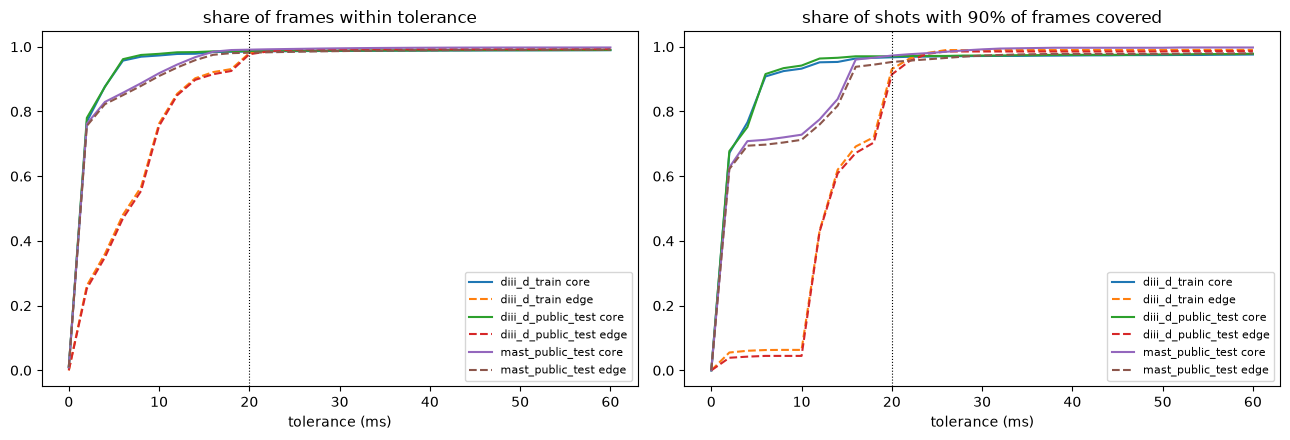

In [11]:
# Coverage against the tolerance: share of frames whose nearest valid slice is within tol, and
# share of shots with at least 90 percent of frames covered, per split and system.
TOLERANCES_MS = np.arange(0, 61, 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
coverage_rows = []
for split in SPLITS:
    df = read(split, ["shot", "ts_core_dt_ms", "ts_edge_dt_ms"])
    for system in ("core", "edge"):
        dt = df[f"ts_{system}_dt_ms"]
        frame_share = [float((dt <= tol).mean()) for tol in TOLERANCES_MS]
        shot_share = [float((df.assign(ok=dt <= tol).groupby("shot")["ok"].mean() >= 0.9).mean())
                      for tol in TOLERANCES_MS]
        style = "-" if system == "core" else "--"
        axes[0].plot(TOLERANCES_MS, frame_share, style, label=f"{split} {system}")
        axes[1].plot(TOLERANCES_MS, shot_share, style, label=f"{split} {system}")
        at_build = float((dt <= PARAMS["thomson_tol_ms"]).mean())
        coverage_rows.append({"split": split, "system": system, "frames_within_build_tol": at_build,
                              "frames_within_10ms": float((dt <= 10).mean()), "frames_without_any": float(dt.isna().mean())})
for ax, title in zip(axes, ("share of frames within tolerance", "share of shots with 90% of frames covered")):
    ax.axvline(PARAMS["thomson_tol_ms"], color="k", lw=0.8, ls=":")
    ax.set_xlabel("tolerance (ms)")
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
display(pd.DataFrame(coverage_rows).round(4))

In [12]:
no_thomson = index[index["error"].isna() & ~index["ts_core_any_valid"].fillna(False)]
print(f"{len(no_thomson)} shots with no valid core profile")
display(no_thomson[["split", "shot", "n_frames", "ts_edge_any_valid"]])
no_edge = index[index["error"].isna() & ~index["ts_edge_any_valid"].fillna(False)]
print(f"{len(no_edge)} shots with no valid edge profile")

69 shots with no valid core profile


,split,shot,n_frames,ts_edge_any_valid
121,diii_d_public_test,2256b2a142,7,True
216,diii_d_public_test,3a6c0e063d,94,True
296,diii_d_public_test,5304eb2451,235,False
576,diii_d_public_test,a624c5f533,236,False
633,diii_d_public_test,b48fed2c3f,92,True
...,...,...,...,...
7547,diii_d_train,f237fd6151,18,True
7712,diii_d_train,f87ba1f478,3,True
7726,diii_d_train,f9339ebb8d,2,True
7894,diii_d_train,ff216b3b28,214,False


63 shots with no valid edge profile


## 5. Column profile (B1)

For every column: range, percentiles, missing fraction and share of exact zeros, from
`column_profile.parquet`. Then histograms of the shared quantities for DIII-D training,
DIII-D test and MAST side by side, and the shaping-coil currents per machine. The
question for each input column is whether it is usable as it is, needs scaling, or is
dropped.

In [13]:
profile_path = REPORT_DIR / "column_profile.parquet"
if profile_path.is_file():
    profile = pd.read_parquet(profile_path)
    show = ["split", "column", "role", "n", "missing_frac", "zero_frac", "min", "p01", "p50", "p99", "max"]
    for split in SPLITS:
        sub = profile[(profile["split"] == split) & profile["role"].isin(["input", "flag", "label"])]
        print(split)
        with pd.option_context("display.max_rows", None, "display.max_columns", None,
                               "display.width", 250):
            display(sub[show].round(4).reset_index(drop=True))
else:
    print(f"no profile at {profile_path}; run scripts/profile_frame_table.py --table-dir {TABLE_DIR} --out {REPORT_DIR}")

diii_d_train


,split,column,role,n,missing_frac,zero_frac,min,p01,p50,p99,max
0,diii_d_train,ip__nearest,input,1559340,0.0,0.0000,-1679.7244,-1197.6396,982.5326,1783.1083,2237.0486
1,diii_d_train,ip__mean,input,1559340,0.0,0.0000,-1674.8762,-1194.7787,983.4175,1783.4951,2233.1577
2,diii_d_train,ip__rate,input,1559340,0.0,0.0000,-189340.0625,-2166.2483,70.6724,2233.7763,38265.3320
3,diii_d_train,sol__nearest,input,1559340,0.0,0.0001,-67.0751,-54.0854,-7.3101,37.5927,65.8386
4,diii_d_train,sol__mean,input,1559340,0.0,0.0000,-67.0821,-54.0872,-7.3103,37.5887,65.8655
...,...,...,...,...,...,...,...,...,...,...,...
97,diii_d_train,efit_z_axis,label,1559340,0.0,0.0000,-0.4650,-0.1075,-0.0192,0.0863,0.7854
98,diii_d_train,efit_lcfs_n,label,1559340,0.0,0.0000,37.0000,74.0000,87.0000,93.0000,110.0000
99,diii_d_train,psi_min,label,1559340,0.0,0.0000,-0.5748,-0.4847,-0.2686,0.0838,0.4310
100,diii_d_train,psi_max,label,1559340,0.0,0.0000,-0.3564,-0.1544,0.3699,0.8681,1.1080


diii_d_public_test


,split,column,role,n,missing_frac,zero_frac,min,p01,p50,p99,max
0,diii_d_public_test,ip__nearest,input,193359,0.0,0.0000,-1418.5826,-1191.2310,982.2247,1759.4474,2201.6487
1,diii_d_public_test,ip__mean,input,193359,0.0,0.0000,-1412.2886,-1190.3315,983.1097,1759.6498,2203.3271
2,diii_d_public_test,ip__rate,input,193359,0.0,0.0000,-212770.7188,-2100.5159,74.1115,2186.5996,19486.3652
3,diii_d_public_test,sol__nearest,input,193359,0.0,0.0001,-66.0832,-53.1071,-7.1331,37.7016,61.9322
4,diii_d_public_test,sol__mean,input,193359,0.0,0.0000,-66.0603,-53.0999,-7.1331,37.6998,61.9385
...,...,...,...,...,...,...,...,...,...,...,...
88,diii_d_public_test,ip_shift_ms,flag,193359,0.0,0.0000,-3357.3945,-3311.3345,-3135.5161,-49.4129,48.5871
89,diii_d_public_test,ip_over_peak,flag,193359,0.0,0.0000,0.1134,0.3697,0.9826,0.9982,1.1166
90,diii_d_public_test,inputs_complete,flag,193359,0.0,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
91,diii_d_public_test,ts_core_valid,flag,193359,0.0,0.0131,0.0000,0.0000,1.0000,1.0000,1.0000


mast_public_test


,split,column,role,n,missing_frac,zero_frac,min,p01,p50,p99,max
0,mast_public_test,ip__nearest,input,69075,0.0,0.0000,81.3151,243.7692,631.9465,908.0015,1188.7701
1,mast_public_test,ip__mean,input,69075,0.0,0.0000,80.6664,243.9615,631.9860,907.8048,1109.7977
2,mast_public_test,ip__rate,input,69075,0.0,0.0000,-100674.6328,-8935.3363,51.5305,7047.8763,25953.5664
3,mast_public_test,sol__nearest,input,69075,0.0,0.0000,-48.2594,-45.5690,-24.0793,14.8801,43.3012
4,mast_public_test,sol__mean,input,69075,0.0,0.0000,-48.2334,-45.5640,-24.0803,14.8739,43.3881
...,...,...,...,...,...,...,...,...,...,...,...
67,mast_public_test,ip_shift_ms,flag,69075,0.0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
68,mast_public_test,ip_over_peak,flag,69075,0.0,0.0000,0.1207,0.3462,0.9732,1.0164,1.3139
69,mast_public_test,inputs_complete,flag,69075,0.0,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
70,mast_public_test,ts_core_valid,flag,69075,0.0,0.0090,0.0000,1.0000,1.0000,1.0000,1.0000


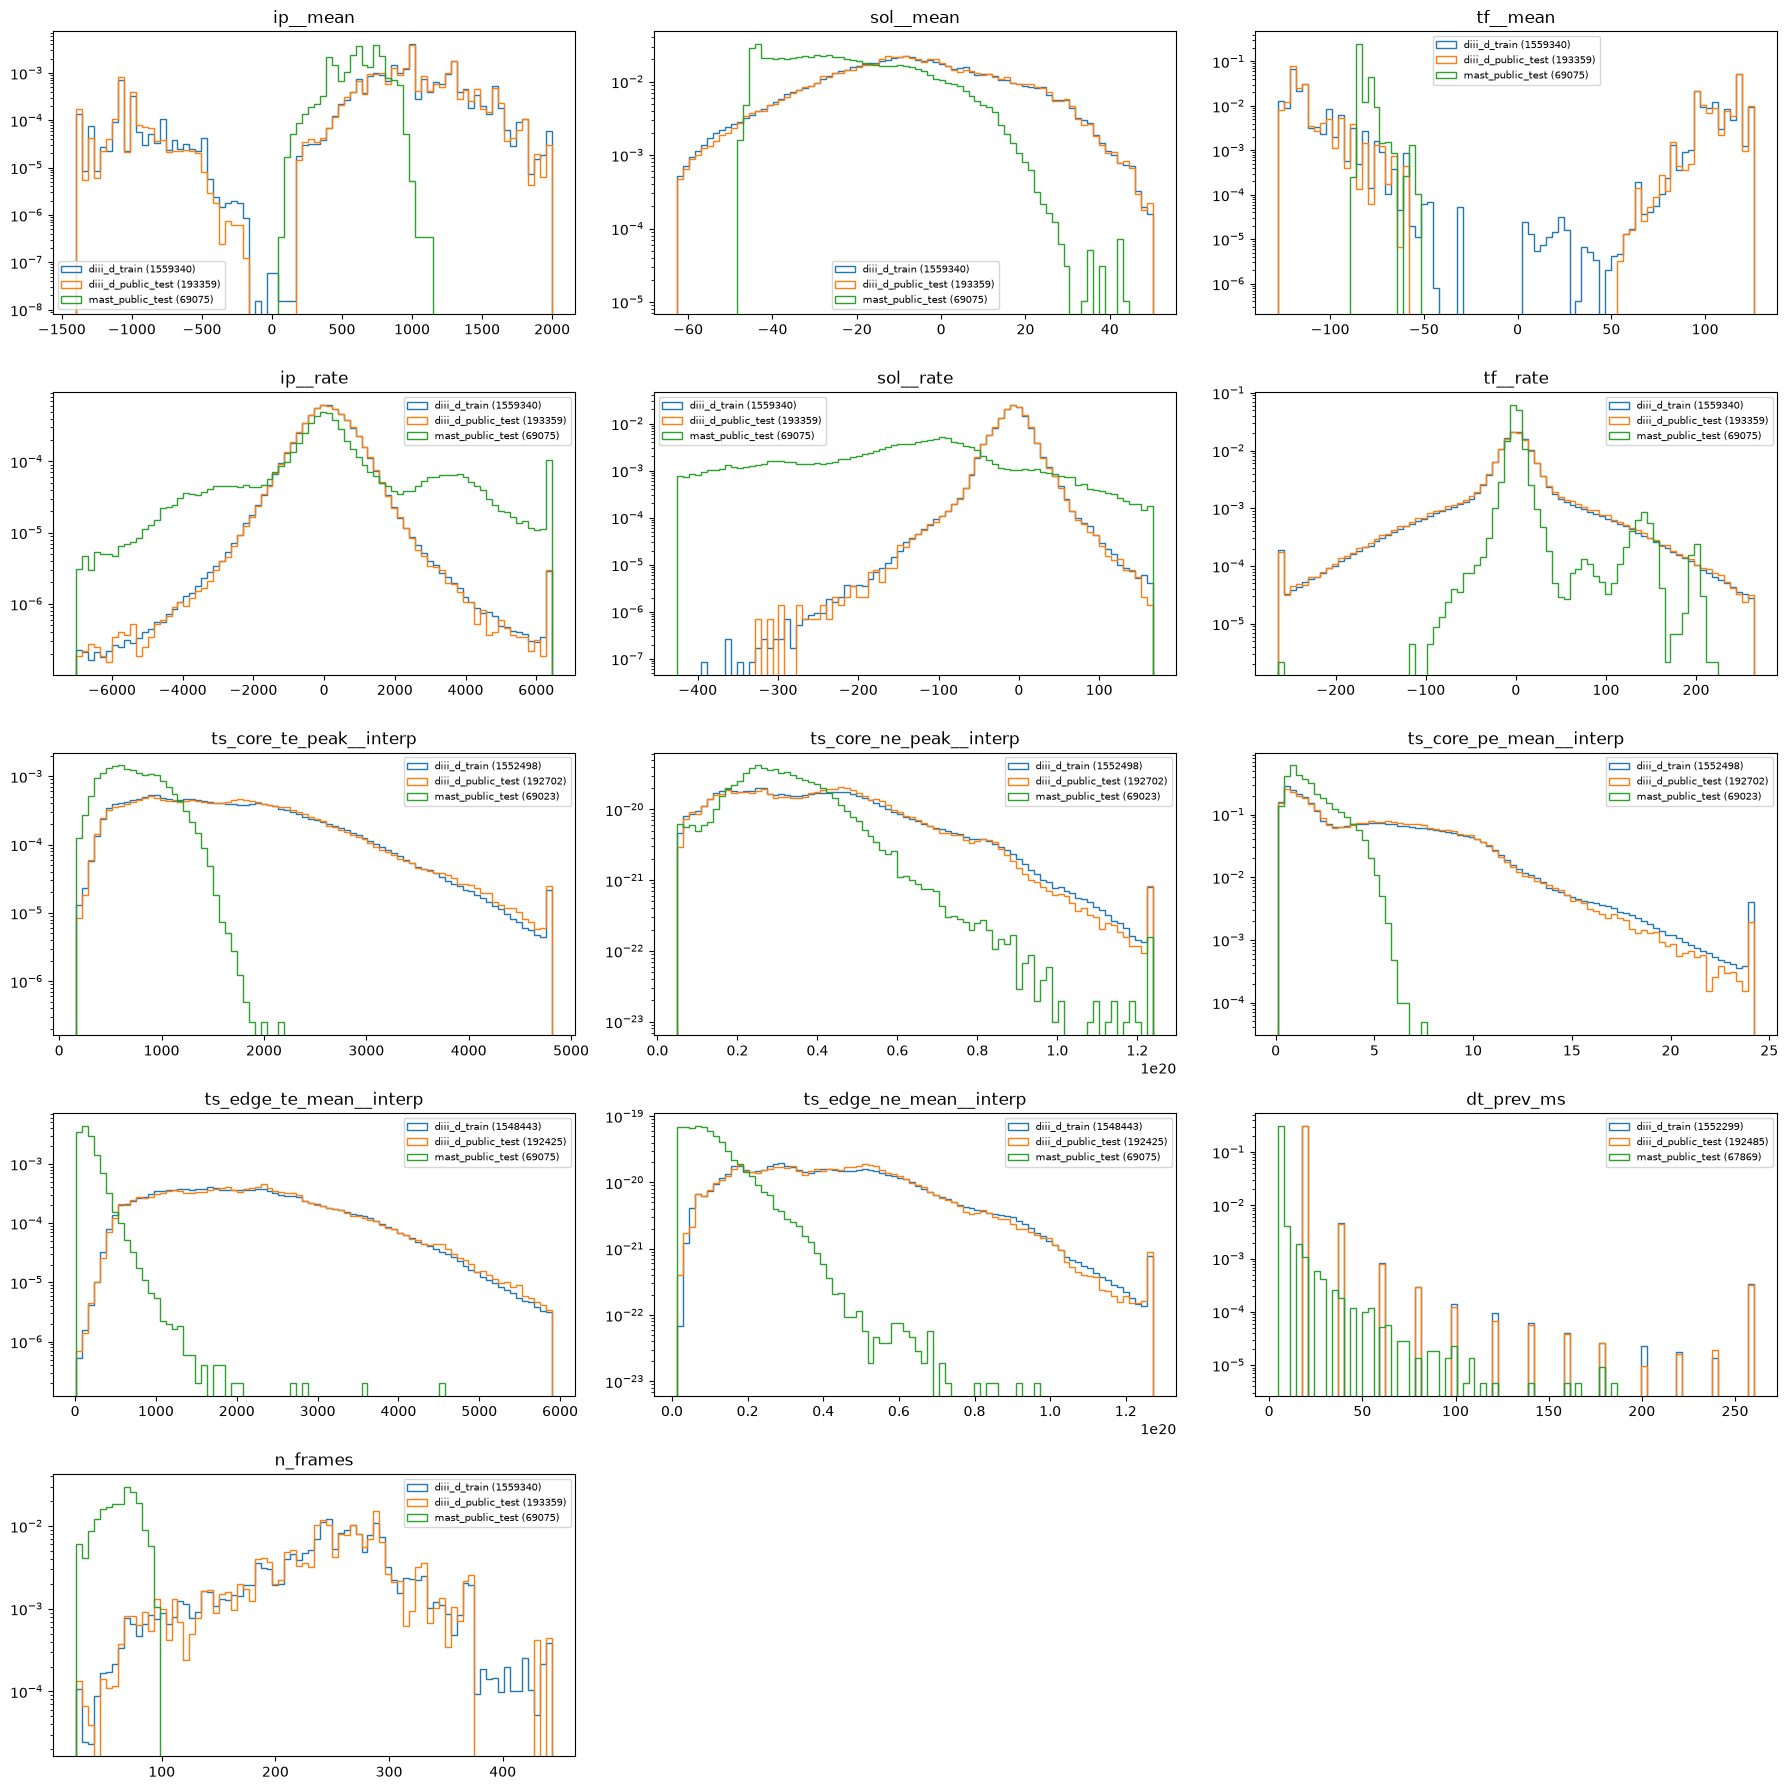

In [14]:
SHARED = ["ip__mean", "sol__mean", "tf__mean", "ip__rate", "sol__rate", "tf__rate",
          "ts_core_te_peak__interp", "ts_core_ne_peak__interp", "ts_core_pe_mean__interp",
          "ts_edge_te_mean__interp", "ts_edge_ne_mean__interp", "dt_prev_ms", "n_frames"]
shared = {split: read(split, SHARED) for split in SPLITS}
ncol = 3
nrow = int(np.ceil(len(SHARED) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 3.6 * nrow))
for ax, col in zip(axes.ravel(), SHARED):
    values = pd.concat([shared[s][col] for s in SPLITS]).dropna()
    lo, hi = values.quantile([0.001, 0.999]) if len(values) else (0, 1)
    if lo == hi:
        lo, hi = lo - 1, hi + 1
    bins = np.linspace(lo, hi, 81)
    for split in SPLITS:
        v = shared[split][col].dropna()
        ax.hist(v.clip(lo, hi), bins=bins, histtype="step", density=True, label=f"{split} ({v.notna().sum()})")
    ax.set_title(col)
    ax.set_yscale("log")
    ax.legend(fontsize=7)
for ax in axes.ravel()[len(SHARED):]:
    ax.axis("off")
fig.tight_layout()

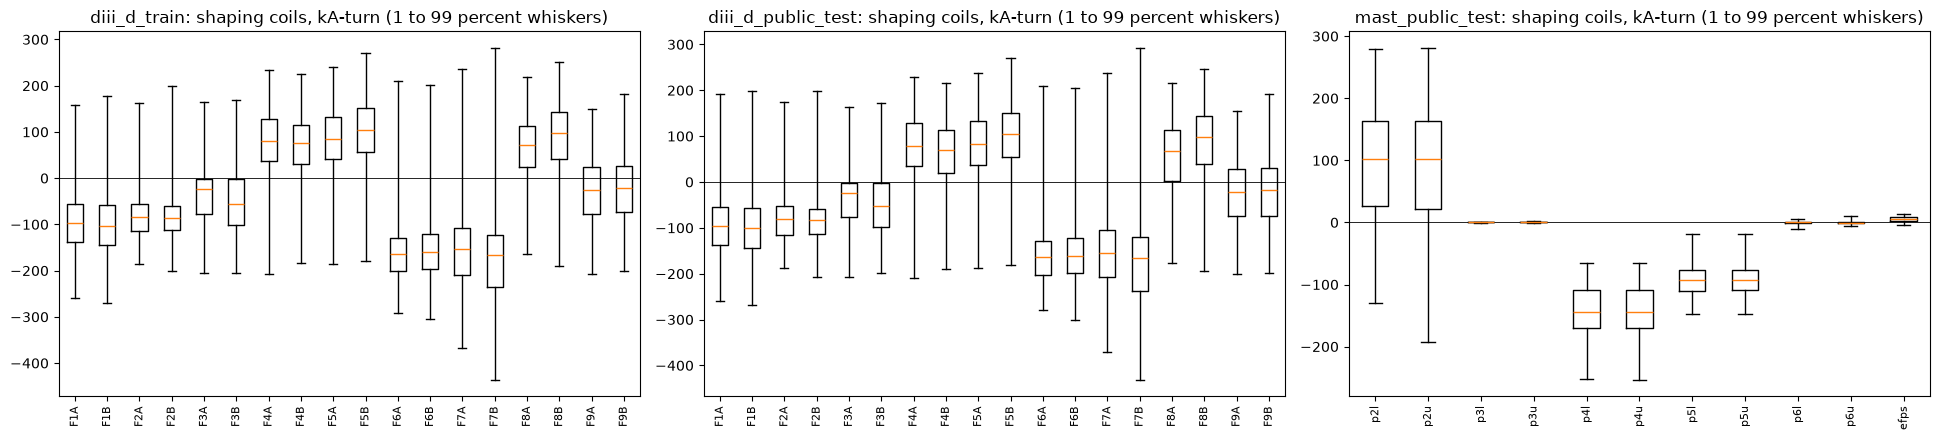

In [15]:
# Shaping-coil currents per machine: distribution of the windowed mean per coil.
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6.5 * len(SPLITS), 4.5), squeeze=False)
for ax, split in zip(axes[0], SPLITS):
    cfg = machine_config(MACHINE_OF[split])
    cols = [f"{c}__mean" for c in cfg.shaping_coil_columns] + [f"{c}__mean" for c in cfg.extra_current_columns]
    df = read(split, cols)
    data = [df[c].dropna().to_numpy() for c in cols]
    ax.boxplot(data, whis=(1, 99), showfliers=False)
    ax.set_xticks(range(1, len(cols) + 1))
    ax.set_xticklabels([c.replace("magnetics_", "").replace("__mean", "").replace("_current", "") for c in cols],
                       rotation=90, fontsize=8)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{split}: shaping coils, kA-turn (1 to 99 percent whiskers)")
fig.tight_layout()

## 6. Relationships (B6), DIII-D training frames

A first read on which targets follow simple combinations of the inputs: flux range
(`psi_max` minus `psi_min`) against absolute Ip; `efit_beta_n` against the core electron
pressure; `efit_q95` against absolute `tf` over absolute `ip`; and the correlation matrix
of the coil currents. A fixed-seed sample of shots keeps the scatter plots readable.

flux range vs |Ip|     Pearson r = 0.900 over 64616 frames
betaN vs core pe       Pearson r = 0.747 over 63870 frames
q95 vs |tf|/|ip|       Pearson r = 0.867 over 64616 frames


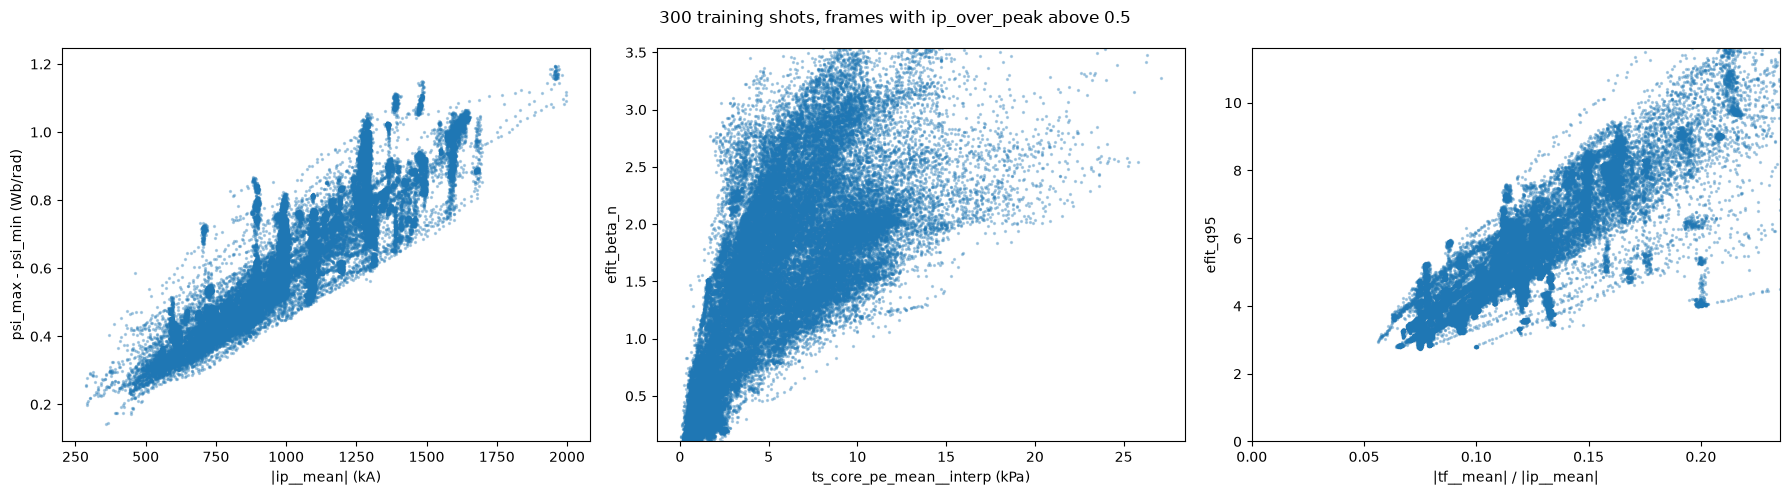

In [16]:
if "diii_d_train" in SPLITS:
    cfg = machine_config("DIII-D")
    rng = np.random.default_rng(SEED)
    train_shots = sorted(index.loc[(index["split"] == "diii_d_train") & index["error"].isna(), "shot"])
    sample = sorted(rng.choice(train_shots, size=min(300, len(train_shots)), replace=False))
    rel = read("diii_d_train", ["shot", "ip__mean", "tf__mean", "ip_over_peak", "psi_min", "psi_max",
                                "efit_beta_n", "efit_q95", "ts_core_pe_mean__interp", "ts_core_valid"], sample)
    rel = rel[rel["ip_over_peak"] > 0.5]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(rel["ip__mean"].abs(), rel["psi_max"] - rel["psi_min"], s=2, alpha=0.3)
    axes[0].set_xlabel("|ip__mean| (kA)")
    axes[0].set_ylabel("psi_max - psi_min (Wb/rad)")
    ok = rel["ts_core_valid"]
    axes[1].scatter(rel.loc[ok, "ts_core_pe_mean__interp"], rel.loc[ok, "efit_beta_n"], s=2, alpha=0.3)
    axes[1].set_xlabel("ts_core_pe_mean__interp (kPa)")
    axes[1].set_ylabel("efit_beta_n")
    axes[1].set_ylim(np.nanpercentile(rel["efit_beta_n"], [0.5, 99.5]))
    ratio = rel["tf__mean"].abs() / rel["ip__mean"].abs()
    axes[2].scatter(ratio, rel["efit_q95"], s=2, alpha=0.3)
    axes[2].set_xlabel("|tf__mean| / |ip__mean|")
    axes[2].set_ylabel("efit_q95")
    axes[2].set_ylim(0, np.nanpercentile(rel["efit_q95"], 99.5))
    axes[2].set_xlim(0, np.nanpercentile(ratio, 99.5))
    fig.suptitle(f"{len(sample)} training shots, frames with ip_over_peak above 0.5")
    fig.tight_layout()
    for x, y, name in ((rel["ip__mean"].abs(), rel["psi_max"] - rel["psi_min"], "flux range vs |Ip|"),
                       (rel.loc[ok, "ts_core_pe_mean__interp"], rel.loc[ok, "efit_beta_n"], "betaN vs core pe"),
                       (ratio, rel["efit_q95"], "q95 vs |tf|/|ip|")):
        m = np.isfinite(x) & np.isfinite(y)
        print(f"{name:22s} Pearson r = {np.corrcoef(x[m], y[m])[0, 1]:.3f} over {int(m.sum())} frames")

most correlated pairs:


magnetics_F1A__mean  magnetics_F1B__mean    0.961
ip__mean             magnetics_F6A__mean    0.941
magnetics_F6A__mean  magnetics_F6B__mean    0.935
ip__mean             magnetics_F6B__mean    0.926
                     magnetics_F2B__mean    0.843
magnetics_F2A__mean  magnetics_F2B__mean    0.833
ip__mean             magnetics_F7B__mean    0.825
                     magnetics_F7A__mean    0.816
                     magnetics_F5B__mean    0.816
magnetics_F1B__mean  magnetics_F7A__mean    0.809
magnetics_F1A__mean  magnetics_F7A__mean    0.808
magnetics_F2B__mean  magnetics_F6A__mean    0.807
dtype: float64

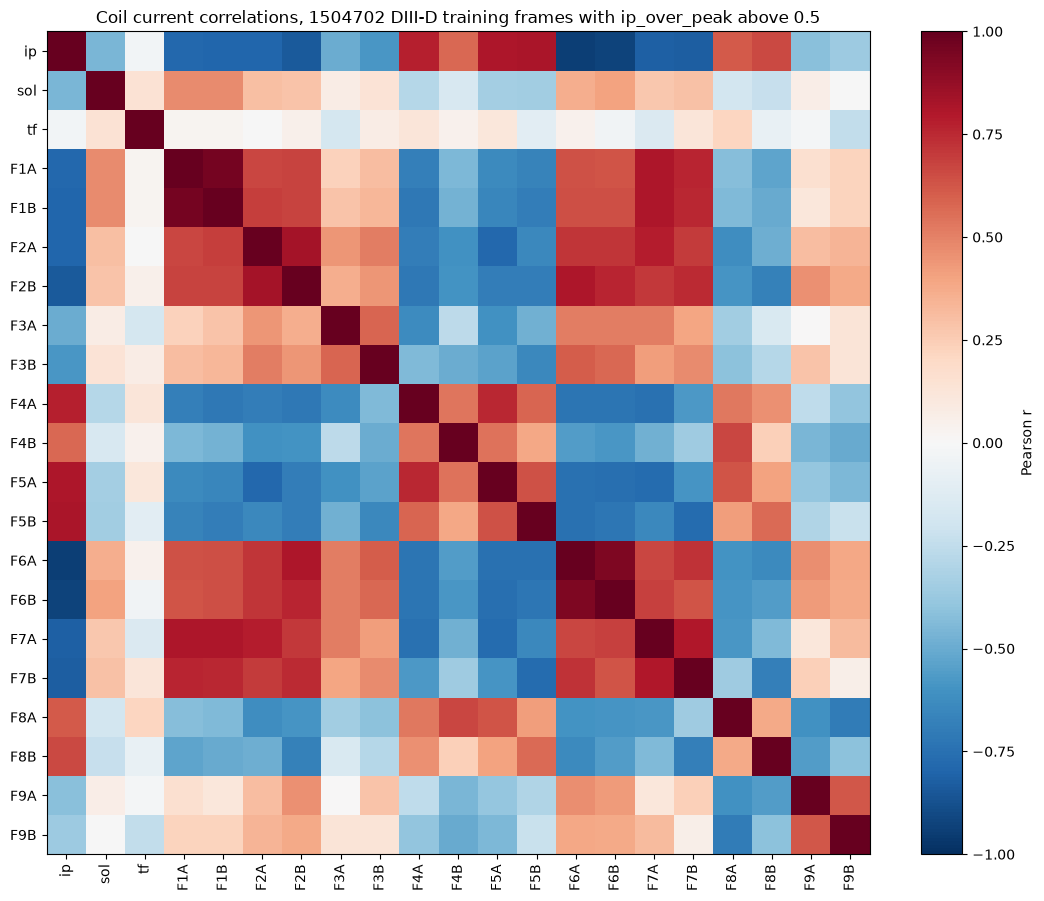

In [17]:
if "diii_d_train" in SPLITS:
    cfg = machine_config("DIII-D")
    coil_cols = ["ip__mean", "sol__mean", "tf__mean"] + [f"{c}__mean" for c in cfg.shaping_coil_columns]
    coils = read("diii_d_train", coil_cols + ["ip_over_peak"])
    coils = coils[coils["ip_over_peak"] > 0.5].drop(columns="ip_over_peak")
    corr = coils.corr()
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    labels = [c.replace("magnetics_", "").replace("__mean", "") for c in corr.columns]
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    fig.colorbar(im, ax=ax, label="Pearson r")
    ax.set_title(f"Coil current correlations, {len(coils)} DIII-D training frames with ip_over_peak above 0.5")
    fig.tight_layout()
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
    print("most correlated pairs:")
    display(pairs.abs().sort_values(ascending=False).head(12).round(3))

## 7. Findings

The decision reached on each item of the phase, with the evidence from the sections
above. Findings F26 to F44 in `docs/findings.md` record the full build of 6 October 2026.

| Item | Options | Decision | Evidence |
| --- | --- | --- | --- |
| Resampling of currents (A2) | nearest sample; windowed mean, and its window length | Windowed mean over 2 ms, provisional until the ridge comparison in the baseline phase (F28) | sections 2 and 3 |
| Rate-of-change window (A4) | 10 ms, or longer if the two recording rates differ in noise | 10 ms is too short: the flat-top spread of `ip__rate` is as large as a typical ramp and 1.3 to 1.4 times wider at 2 kHz; a 50 ms rate is added at the next rebuild (F32) | section 3 |
| Thomson in time (A3) | interpolation between valid slices; nearest slice within a tolerance | Interpolation between valid slices (F34) | section 4 |
| Thomson validity tolerance | 20 ms, or another value read off the coverage curve | 20 ms core, 25 ms edge, derived from the stored distance columns without a rebuild (F35) | section 4 |
| Usable inputs (B1) | per column: usable as is, needs scaling, or dropped | Currents in the mean form usable as they are; rates not usable as built; core Thomson usable with clipping (F37) and the validity flag; edge Thomson not comparable across machines (F38) | section 5 |
| First read on linearity (B6) | which targets follow simple combinations of the inputs | Flux range follows Ip (r 0.90), q95 follows tf over Ip (r 0.87), betaN follows core pressure (r 0.75); coil currents are strongly correlated with each other and with Ip (F41, F42) | section 6 |

Unexpected observations:

- F30: the MAST P3 coils carry almost no current during the plasma, so the two resampling
  forms differ by 11 to 16 percent of their spread.
- F33: MAST plasmas change several times faster than DIII-D plasmas; raw rates do not
  transfer.
- F37: DIII-D core Thomson summaries contain rare extreme values, up to 12,212 eV and 251 kPa.
- F38: the "edge" Thomson system measures different regions on the two machines (median
  edge Te 1,980 eV on DIII-D against 143 eV on MAST).
- F44: some training frames have almost no plasma current (`ip_over_peak` down to 0.000).

Follow-ups (section 8), recorded as open items 7 to 9 of `docs/findings.md`, resolved:

- Item 7: the 62 training shots without a valid core Thomson profile against the 53 QA
  reported is a difference of definition on one- and two-frame shots. Five one-frame shots
  have a valid slice within 1.2 ms of their frame but no slice inside their zero-length
  window; one two-frame shot has five slices inside its window, none valid, and valid
  slices 8 to 9 ms outside it. The frame table count of 62 stands.
- Item 8: 1,592 frames with the toroidal field below 50 kA in magnitude, in 11 shots. Nine
  are real low-field or field-ramp shots (q95 1.9 to 3.9). The two shots with q95 below 1,
  `5df1630aa7` and `955c35c962`, carry a field signal of 3 to 27 kA against a plasma current
  of about 1,150 kA, implausible for that current, and their labels scale with it (q95 about
  0.7, betaN about 6). They are candidates for exclusion from scalar training; their flux
  maps are still to be checked, and the decision belongs to the label-quality step (B5).
- Item 9: frames with `ip_over_peak` below 0.1 are 13 in 11 shots, all in the last tenth of
  the shot; below 0.2 are 1,303 (0.084%) in 277 shots, 1,229 of them in the last tenth.
  These are end-of-shot ramp-downs, which a minimum-Ip rule removes at negligible cost.


## 8. Follow-ups

One cell per open item of `docs/findings.md` (items 7 to 9). Item 7 compares the shot
index of this build with the QA per-shot table shot by shot.

In [2]:
# Open item 7: training shots without a valid core Thomson profile, frame table against QA.
# Frame table: ts_core_any_valid is False when no frame has a valid slice (at least half the
# channels with both Te and ne present) within thomson_tol_ms of it, counting slices at any
# time. QA 0.7: tsm_core_frames_valid_within_20ms is the share of frames within 20 ms of a
# valid slice counting only slices inside the EFIT window; it is NaN when no slice lies there.
qa_ts = pd.read_parquet(QA_TABLE, columns=["split", "shot", "tsm_core_frames_valid_within_20ms",
                                          "tsm_core_n_times", "tsm_core_n_times_window", "tsm_core_n_channels"])
train = index[(index["split"] == "diii_d_train") & index["error"].isna()][["shot", "n_frames", "ts_core_any_valid"]]
merged = train.merge(qa_ts[qa_ts["split"] == "diii_d_train"].drop(columns="split"), on="shot", how="left")
coverage = merged["tsm_core_frames_valid_within_20ms"]
merged["qa_kind"] = np.select([coverage.isna(), coverage == 0], ["no slice in window", "no valid slice"], default="covered")
merged["qa_none"] = merged["qa_kind"] != "covered"
merged["ft_none"] = ~merged["ts_core_any_valid"].fillna(False)
display(pd.crosstab(merged["qa_kind"], merged["ft_none"], margins=True))
differ = merged[merged["qa_none"] != merged["ft_none"]]
print(f"{len(differ)} shots differ between the two definitions")
display(differ[["shot", "n_frames", "ts_core_any_valid", "qa_kind", "tsm_core_n_times",
                "tsm_core_n_times_window", "tsm_core_n_channels"]])

ft_none,False,True,All
qa_kind,,,
covered,6973,0,6973
no slice in window,5,10,15
no valid slice,1,52,53
All,6979,62,7041


6 shots differ between the two definitions


,shot,n_frames,ts_core_any_valid,qa_kind,tsm_core_n_times,tsm_core_n_times_window,tsm_core_n_channels
1435,316f541fd6,1,True,no slice in window,3047.0,0.0,44.0
3914,8c2c362dfd,1,True,no slice in window,2317.0,0.0,44.0
4236,98106629ab,1,True,no slice in window,2986.0,0.0,44.0
5081,b722acb466,1,True,no slice in window,3047.0,0.0,44.0
5912,d4fc5902f4,1,True,no slice in window,3047.0,0.0,44.0
6628,f0a33e7fe4,2,True,no valid slice,3007.0,5.0,44.0


In [3]:
# The differing shots in detail: distance from each frame to the nearest valid slice (any
# time) against the EFIT window, so the reason for each difference is visible.
if len(differ):
    detail = read("diii_d_train", ["shot", "frame", "time_ms", "ts_core_dt_ms", "ts_core_valid"], sorted(differ["shot"]))
    summary = detail.groupby("shot").agg(frames=("frame", "size"), window_start_ms=("time_ms", "min"),
                                         window_end_ms=("time_ms", "max"), dt_min_ms=("ts_core_dt_ms", "min"),
                                         dt_median_ms=("ts_core_dt_ms", "median"),
                                         frames_valid=("ts_core_valid", "sum"))
    display(summary.merge(differ.set_index("shot")[["qa_kind", "tsm_core_n_times"]], left_index=True, right_index=True))

,frames,window_start_ms,window_end_ms,dt_min_ms,dt_median_ms,frames_valid,qa_kind,tsm_core_n_times
shot,,,,,,,,
316f541fd6,1,5060.0,5060.0,0.015137,0.015137,1,no slice in window,3047.0
8c2c362dfd,1,1600.0,1600.0,0.000977,0.000977,1,no slice in window,2317.0
98106629ab,1,120.0,120.0,1.146004,1.146004,1,no slice in window,2986.0
b722acb466,1,580.0,580.0,0.010010,0.010010,1,no slice in window,3047.0
d4fc5902f4,1,180.0,180.0,0.001999,0.001999,1,no slice in window,3047.0
f0a33e7fe4,2,1740.0,1760.0,8.279053,8.969055,2,no valid slice,3007.0


1592 frames with |tf__mean| below 50 kA in 11 shots, of 1559340 frames


,low_frames,n_frames,first_frame,last_frame,tf_abs_min,tf_abs_max,q95_min,q95_median,ip_over_peak_median
shot,,,,,,,,,
5df1630aa7,316,316,0,315,3.872921,27.131884,0.170922,0.724662,0.976362
955c35c962,292,292,0,291,3.265544,25.134686,0.165976,0.642139,0.975671
d597b8ec22,234,237,0,236,46.828762,49.929955,3.431333,3.877872,0.953682
8dffbfc783,220,220,0,219,46.768024,49.844208,3.443474,3.715661,0.952087
6fb57bed55,141,141,0,140,29.974863,30.365208,2.289129,3.154835,0.731410
4173ac3d16,126,126,0,125,30.017063,30.401075,2.342444,3.481588,0.685343
e869356e6e,107,107,0,106,45.860531,49.586967,3.307363,3.693074,0.971577
c667d63ad1,78,78,0,77,33.619827,42.593155,1.903589,2.163154,0.987916
341645ad3f,39,241,202,240,44.467506,49.948494,3.371790,3.589159,0.964702


,frames,tf_abs_median,tf_abs_min,ip_abs_median,q95_median,q95_max,beta_n_median
shot,,,,,,,
5df1630aa7,316,18.612530,3.872921,1158.562012,0.724662,1.012879,6.206925
955c35c962,292,17.724688,3.265544,1151.886230,0.642139,0.945519,6.043941


shots in both groups: ['5df1630aa7', '955c35c962']


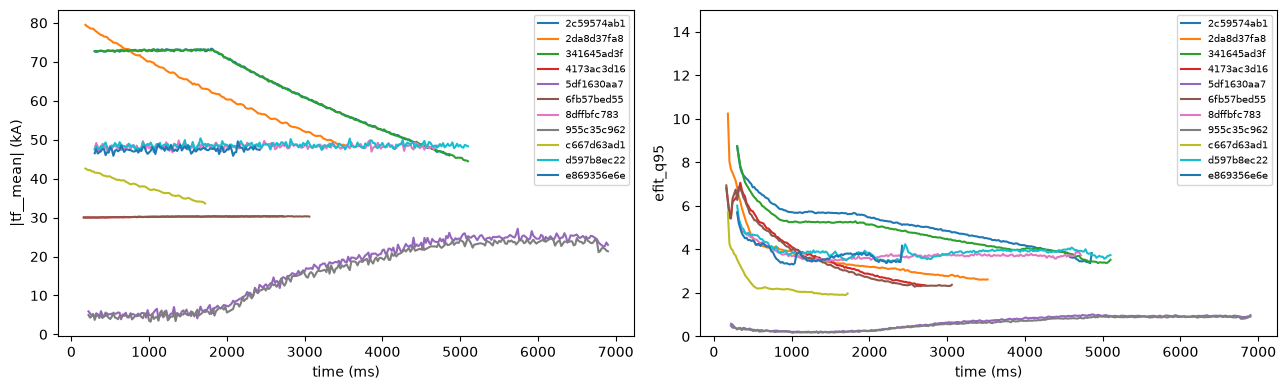

In [4]:
# Open item 8: training frames with |tf__mean| below 50 kA, and the two shots with q95 below 1.
Q95_BELOW_1 = ["5df1630aa7", "955c35c962"]
tf = read("diii_d_train", ["shot", "frame", "time_ms", "n_frames", "tf__mean", "ip__mean", "ip_over_peak",
                           "efit_q95", "efit_beta_n"])
low = tf[tf["tf__mean"].abs() < 50]
print(f"{len(low)} frames with |tf__mean| below 50 kA in {low['shot'].nunique()} shots, of {len(tf)} frames")
per_shot = low.groupby("shot").agg(
    low_frames=("frame", "size"), n_frames=("n_frames", "first"), first_frame=("frame", "min"),
    last_frame=("frame", "max"), tf_abs_min=("tf__mean", lambda s: s.abs().min()),
    tf_abs_max=("tf__mean", lambda s: s.abs().max()), q95_min=("efit_q95", "min"),
    q95_median=("efit_q95", "median"), ip_over_peak_median=("ip_over_peak", "median"))
display(per_shot.sort_values("low_frames", ascending=False))
compare = tf[tf["shot"].isin(Q95_BELOW_1)].groupby("shot").agg(
    frames=("frame", "size"), tf_abs_median=("tf__mean", lambda s: s.abs().median()),
    tf_abs_min=("tf__mean", lambda s: s.abs().min()), ip_abs_median=("ip__mean", lambda s: s.abs().median()),
    q95_median=("efit_q95", "median"), q95_max=("efit_q95", "max"), beta_n_median=("efit_beta_n", "median"))
display(compare)
print("shots in both groups:", sorted(set(per_shot.index) & set(Q95_BELOW_1)))
shots_to_plot = sorted(set(per_shot.index) | set(Q95_BELOW_1))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for shot_id, sub in tf[tf["shot"].isin(shots_to_plot)].groupby("shot"):
    axes[0].plot(sub["time_ms"], sub["tf__mean"].abs(), label=shot_id)
    axes[1].plot(sub["time_ms"], sub["efit_q95"], label=shot_id)
axes[0].set_ylabel("|tf__mean| (kA)")
axes[1].set_ylabel("efit_q95")
axes[1].set_ylim(0, 15)
for ax in axes:
    ax.set_xlabel("time (ms)")
    ax.legend(fontsize=7)
fig.tight_layout()

below 0.1: 13 frames (0.0008%) in 11 shots; in the first tenth of the shot 0, in the last tenth 13, elsewhere 0


,low_frames,n_frames,first_frame,last_frame,ratio_min
shot,,,,,
920cee1641,2,272,270,271,0.097141
f13d935b18,2,93,91,92,0.000888
1188622801,1,123,122,122,0.000178
269e33625f,1,85,84,84,0.059176
3cbb2af6dc,1,157,156,156,0.005706
4ce7c20bec,1,217,216,216,0.000411
69f6fb8ce5,1,229,228,228,0.009704
9a7968e458,1,249,248,248,0.010138
b5f223d2be,1,212,211,211,0.034861


below 0.2: 1303 frames (0.0836%) in 277 shots; in the first tenth of the shot 11, in the last tenth 1229, elsewhere 63


,low_frames,n_frames,first_frame,last_frame,ratio_min
shot,,,,,
d3f657fd23,45,315,270,314,0.111599
f4535d5616,35,152,117,151,0.098032
46b03b025b,29,163,134,162,0.126093
920cee1641,28,272,244,271,0.097141
5fc04c4e25,28,300,272,299,0.138892
250b2b4622,24,297,273,296,0.144777
5feee8ad0c,23,289,266,288,0.143666
88303d2df2,23,292,269,291,0.140469
f8ceb1a705,22,322,300,321,0.140129


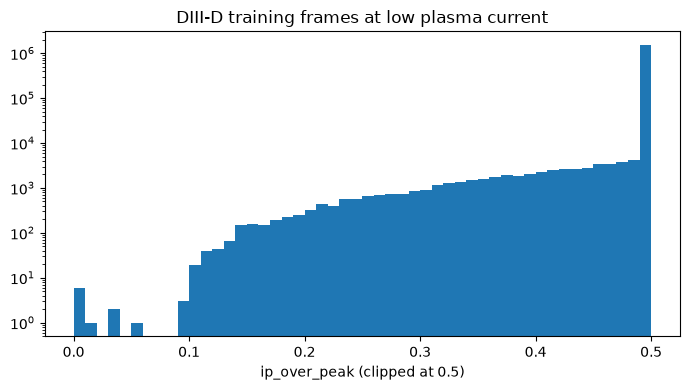

In [5]:
# Open item 9: training frames with ip_over_peak below 0.1 and below 0.2: how many, in which
# shots, and where in the shot (position = frame / (n_frames - 1)).
ipk = read("diii_d_train", ["shot", "frame", "time_ms", "n_frames", "ip_over_peak", "ip__mean"])
for threshold in (0.1, 0.2):
    low = ipk[ipk["ip_over_peak"] < threshold]
    position = low["frame"] / (low["n_frames"] - 1).clip(lower=1)
    print(f"below {threshold}: {len(low)} frames ({len(low) / len(ipk):.4%}) in {low['shot'].nunique()} shots; "
          f"in the first tenth of the shot {int((position <= 0.1).sum())}, in the last tenth {int((position >= 0.9).sum())}, "
          f"elsewhere {int(((position > 0.1) & (position < 0.9)).sum())}")
    per_shot_low = low.groupby("shot").agg(low_frames=("frame", "size"), n_frames=("n_frames", "first"),
                                           first_frame=("frame", "min"), last_frame=("frame", "max"),
                                           ratio_min=("ip_over_peak", "min"))
    display(per_shot_low.sort_values("low_frames", ascending=False).head(20))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ipk["ip_over_peak"].clip(0, 0.5), bins=np.linspace(0, 0.5, 51))
ax.set_yscale("log")
ax.set_xlabel("ip_over_peak (clipped at 0.5)")
ax.set_title("DIII-D training frames at low plasma current")
fig.tight_layout()